# TP3C · Simulador de RedBaires

Este notebook es el simulador con el que se corren los experimentos de la tercera entrega. Sale del simulador de la entrega B, en Python con SimPy, y se lee en el mismo orden: una publicación sola, la cola de moderación con pocos ítems, un día entero y después la calibración y los controles. Las celdas marcadas con la etiqueta `modelo` definen el simulador, y el notebook de experimentos carga sólo esas. El resto son demostraciones.

Respecto de la entrega B cambió lo siguiente. La fracción removida se acumula de forma multiplicativa. Los hijos medios por tipo de cuenta se miden sólo con publicaciones orgánicas y se recalibró la escala. Los parámetros y los costos se calculan de los datos o se leen de `parametros_y_costos.csv`. El volumen pasó de variable de decisión a parámetro del escenario. Se agregaron el fin de semana, el peor episodio del mes, el costo de degradar y controles que frenan la corrida si algo no cierra.

Para correrlo hacen falta los dos CSV del campus en `datos/`.

In [1]:
import numpy as np, pandas as pd, simpy
import matplotlib.pyplot as plt
from scipy import stats, optimize
from scipy.special import gammaincinv

plt.rcParams["figure.figsize"] = (9, 3.2)

RUTA_MUESTRA = "../datos/muestra_cascadas_REDBAIRES.csv"
RUTA_COSTOS = "../datos/parametros_y_costos.csv"
TIPOS = ["BROADCASTER", "CREATOR", "AGGREGATOR", "LURKER", "STANDARD"]
TABLERO = False                                # prende los gráficos del tablero de control

# Lo que no sale de los datos ni del archivo de costos. Son supuestos declarados.
SUPUESTOS = dict(
    escala=57.3,                                 # calibrada en el paso 5
    temas_sensibles=("DISARM", "ORG-POL", "ORG-HLTH"),
    factor_tema_sensible=1.5,                  # remoción más dura en temas sensibles
    factor_verificada=0.5,                     # remoción a la mitad para cuentas verificadas
    tiempo_revision_seg=20,                    # media de cada fase de la Erlang de revisión
    tam_cascada_cortada=500,                   # las cascadas de ese tamaño están truncadas en la muestra
    dias_cuenta_nueva=30,                      # regla de detección de campañas
    ventana_deteccion_min=120,
    tipos_cuenta_grande=("BROADCASTER", "CREATOR"),
    dias_cobrados_por_deteccion=1,
)

# El escenario es lo que la empresa no decide.
ESCENARIO_BASE = dict(volumen=1.0, factor_remocion=1.0, tiempo_revision_seg=None, demora="gamma", m_coord=None)
# Las variables de decisión, con sus valores de hoy.
VD_HOY = dict(c=1, umbral=None, reduccion=0.0, degradar=False, d=0.5, clasificador=None)

## Paso 1 · Los parámetros, desde los datos

Todo lo que el simulador usa se calcula de `muestra_cascadas_REDBAIRES.csv` o se lee de `parametros_y_costos.csv`. Se limpia igual que en la entrega A: sin eventos duplicados y sin las cascadas cortadas en 500 eventos.

| Parámetro | Cómo se obtiene |
|---|---|
| hijos por evento Rᵢ | promedio de `reshare_count_from_actor` por tipo de cuenta, sólo en publicaciones orgánicas |
| multiplicador de campañas m | hijos medios de las coordinadas sobre los de las orgánicas |
| decaimiento δ(g) | hijos medios en la generación g sobre los de la generación 1 |
| impresiones por seguidor | mediana del cociente entre impresiones y seguidores |
| demora entre generaciones | gamma por máxima verosimilitud, y la mezcla de dos canales por mínimos cuadrados sobre la acumulada |
| piso de la latencia | mínimo de `moderation_latency_min` |
| precisión y recall de la detección de campañas | la regla de la entrega A, medida contra el sufijo C2 |
| factor de fin de semana | publicaciones por día de sábados y domingos sobre las de lunes a viernes |
| costos | `parametros_y_costos.csv`. El costo de la impresión nociva suma externalidad y abandono de usuarios |

Los hijos medios se miden sin campañas porque el multiplicador m ya las representa: con todos los eventos, las publicaciones orgánicas quedaban con un R inflado. La entrega B sumaba las fracciones removidas de distintas generaciones, y esa suma sobrestima el efecto de la moderación. El fin de semana mantiene el total semanal y reparte la tasa entre los días.

In [2]:
def costos(ruta=RUTA_COSTOS):
    c = pd.read_csv(ruta).set_index("param").valor_base
    r, vida = c.discount_rate, c.vida_util_clasificador_years
    return dict(
        nociva=c.costo_social_por_impresion_nociva + c.tasa_churn_por_exposicion_nociva * c.valor_marca_por_usuario_activo,
        engagement=c.valor_engagement_por_impresion,
        falso_positivo=c.costo_reputacional_por_falso_positivo,
        item=c.costo_revision_por_item_flag,
        moderador_mes=c.costo_moderador_por_hora * c.horas_operativas_mes,
        degradar_dia=c.costo_degradar_influencer_por_dia,
        clasificador_mes=(c.capex_clasificador_ml * r / (1 - (1 + r) ** -vida) + c.opex_anual_clasificador) / 12,
        perdida_friccion=c.perdida_engagement_por_rate_limit,
    )

def ajustar_mezcla(x, piso):
    """Dos canales: uno directo y otro con demora mínima. Devuelve (p, a1, e1, a2, e2)."""
    xs, emp = np.sort(x), (np.arange(len(x)) + .5) / len(x)
    idx = np.linspace(0, len(xs) - 1, 4000).astype(int)
    cdf = lambda t, p, a1, e1, a2, e2: (p * stats.gamma.cdf(t, a1, scale=e1)
                                        + (1 - p) * stats.gamma.cdf(np.maximum(t - piso, 0), a2, scale=e2))
    r = optimize.minimize(lambda th: np.sum((cdf(xs[idx], *th) - emp[idx]) ** 2), [.6, .6, 40, 1, 50],
                          bounds=[(.3, .9), (.1, 3), (5, 300), (.1, 5), (5, 400)], method="L-BFGS-B")
    return tuple(float(v) for v in r.x), float(np.max(np.abs(cdf(xs, *r.x) - emp)))

def parametros(ruta=RUTA_MUESTRA, escala=None):
    S = SUPUESTOS
    crudo = pd.read_csv(ruta).drop_duplicates("event_id")
    crudo["tipo"] = crudo.account_type_code.str.upper()
    crudo["tipo_i"] = crudo.tipo.map({t: i for i, t in enumerate(TIPOS)})
    crudo["tema"] = crudo.topic_code.str.upper()
    crudo["nociva"] = crudo.tema.str.startswith("DISARM")
    crudo["coord"] = crudo.hashtag_cluster_ref.str.upper().str.endswith("C2")
    tam = crudo.groupby("cascade_id").size()
    d = crudo[~crudo.cascade_id.isin(tam[tam >= S["tam_cascada_cortada"]].index)].copy()

    P = dict(escala=S["escala"] if escala is None else escala, C=costos())
    P["R"] = d[~d.coord].groupby("tipo").reshare_count_from_actor.mean().reindex(TIPOS).to_numpy()
    hijos_g = d.groupby("cascade_depth").reshare_count_from_actor.mean()
    P["delta"] = (hijos_g / hijos_g.loc[1]).to_numpy()
    P["m_coord"] = d[d.coord].reshare_count_from_actor.mean() / d[~d.coord].reshare_count_from_actor.mean()
    P["p_hijo"] = d[d.seed_flag == 0].tipo.value_counts(normalize=True).reindex(TIPOS).to_numpy()
    P["seguidores"] = [d[d.tipo == t].actor_follower_count.to_numpy() for t in TIPOS]
    P["verif"] = d.groupby("tipo").verified_flag.mean().reindex(TIPOS).to_numpy()
    P["cortes_tox"] = d.toxicity_index.quantile([.2, .4, .6, .8]).to_numpy()
    d["quintil"] = np.searchsorted(P["cortes_tox"], d.toxicity_index)
    P["p_marca"] = d.groupby(["nociva", "quintil"]).moderation_flag.mean().unstack().to_numpy()
    P["frac_nociva_ev"] = d.nociva.mean()
    r = d.dropna(subset=["impressions"]); r = r[r.actor_follower_count > 0]
    P["imp_por_seguidor"] = float((r.impressions / r.actor_follower_count).median())
    P["piso_latencia"] = float(d.loc[d.moderation_flag == 1, "moderation_latency_min"].min())

    x = crudo.loc[crudo.seed_flag == 0, "inter_event_time_min"].dropna(); x = x[x > 0].to_numpy()
    a, _, e = stats.gamma.fit(x, floc=0)
    P["gamma"], P["demoras"] = (float(a), float(e)), x
    h, _ = np.histogram(x, np.arange(0, 301))
    P["piso_mezcla"] = int(np.argmax(np.diff(h)) + 1)
    P["mezcla"], P["D_mezcla"] = ajustar_mezcla(x, P["piso_mezcla"])

    t = pd.to_datetime(crudo.forward_datetime, errors="coerce")
    t0 = t[crudo.seed_flag == 1].groupby(crudo.cascade_id).first()
    desde = (t - crudo.cascade_id.map(t0)).dt.total_seconds() / 60
    nuevas = (desde >= 0) & (desde <= S["ventana_deteccion_min"]) & (crudo.account_age_days < S["dias_cuenta_nueva"])
    casc = crudo.groupby("cascade_id").coord.max().to_frame()
    casc["det"] = casc.index.isin(crudo.loc[nuevas, "cascade_id"])
    P["recall_det"] = float((casc.coord & casc.det).sum() / casc.coord.sum())
    P["precision_det"] = float((casc.coord & casc.det).sum() / casc.det.sum())

    sem = d[d.seed_flag == 1]
    P["semillas"] = sem[["tipo_i", "tema", "nociva", "coord", "toxicity_index"]].reset_index(drop=True)
    P["frac_coord"] = sem.coord.mean()
    fecha = pd.to_datetime(sem.forward_datetime, errors="coerce")
    fecha = fecha[fecha.dt.year < 2030]
    P["por_dia"] = fecha.dt.date.value_counts().sort_index()
    finde = pd.to_datetime(P["por_dia"].index).dayofweek >= 5
    P["factor_finde"] = float(P["por_dia"][finde].mean() / P["por_dia"][~finde].mean())
    m = 7 / (5 + 2 * P["factor_finde"])
    P["semana"] = np.array([m] * 5 + [m * P["factor_finde"]] * 2)      # la corrida arranca un lunes
    horas = pd.to_datetime(sem.forward_datetime, errors="coerce").dt.hour
    P["lam_base"] = horas.value_counts().reindex(range(24), fill_value=0).to_numpy() / len(P["por_dia"]) / 60
    P["lam"] = P["lam_base"] * P["escala"]
    P["grandes"] = [TIPOS.index(t) for t in S["tipos_cuenta_grande"]]
    assert P["delta"][-1] == 0, "la generación más profunda de la muestra tiene hijos: revisar δ"
    return P, d

def con_escala(P, escala):
    return {**P, "escala": escala, "lam": P["lam_base"] * escala}

P, datos = parametros()

In [3]:
print("R (orgánicas):", dict(zip(TIPOS, P["R"].round(2))), "  m:", round(P["m_coord"], 3))
print("gamma: forma", round(P["gamma"][0], 3), "escala", round(P["gamma"][1], 1), "min")
print("mezcla: directo", round(P["mezcla"][0], 3), " piso", P["piso_mezcla"], "min  D =", round(P["D_mezcla"], 4))
print("impresiones por seguidor:", round(P["imp_por_seguidor"], 4), "  piso de latencia:", P["piso_latencia"], "min")
print("detección de campañas: precisión", round(P["precision_det"], 3), " recall", round(P["recall_det"], 3))
print("costos:", {k: round(v, 5) for k, v in P["C"].items()})

R (orgánicas): {'BROADCASTER': np.float64(4.34), 'CREATOR': np.float64(3.44), 'AGGREGATOR': np.float64(0.54), 'LURKER': np.float64(0.56), 'STANDARD': np.float64(0.55)}   m: 1.076
gamma: forma 0.545 escala 128.5 min
mezcla: directo 0.585  piso 55 min  D = 0.0114
impresiones por seguidor: 0.1525   piso de latencia: 90.0 min
detección de campañas: precisión 0.208  recall 0.467
costos: {'nociva': np.float64(0.00592), 'engagement': np.float64(0.0009), 'falso_positivo': np.float64(1.5), 'item': np.float64(0.12), 'moderador_mes': np.float64(15840.0), 'degradar_dia': np.float64(120.0), 'clasificador_mes': np.float64(11572.30841), 'perdida_friccion': np.float64(0.15)}


El fin de semana no se escribe a mano. Se cuentan las publicaciones de cada uno de los días de la muestra y se comparan sábados y domingos con el resto, con una prueba de Mann-Whitney porque los días son pocos y no hace falta suponer normalidad. La entrega A había redondeado este factor a un 20 %.

In [4]:
por_dia = P["por_dia"]
dia = pd.to_datetime(por_dia.index).dayofweek
tabla = pd.DataFrame({"días": por_dia.groupby(dia).size().to_numpy(), "publicaciones por día": por_dia.groupby(dia).mean().round(2).to_numpy()},
                     index=["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
u = stats.mannwhitneyu(por_dia[dia >= 5], por_dia[dia < 5], alternative="greater")
print(f"factor de fin de semana: {P['factor_finde']:.3f}   Mann-Whitney p = {u.pvalue:.2e}")
tabla

factor de fin de semana: 1.178   Mann-Whitney p = 4.22e-07


,días,publicaciones por día
lunes,26,27.38
martes,26,25.92
miércoles,26,26.73
jueves,25,24.96
viernes,25,26.64
sábado,26,31.15
domingo,26,30.88


La demora entre generaciones sigue siendo una gamma en el modelo base, y la mezcla de dos canales queda disponible para la sensibilidad. El gráfico Q-Q compara percentil a percentil cada modelo con los datos. La escala logarítmica achica las diferencias de la zona media, que es donde la demora compite con la moderación.

,datos,gamma,mezcla
5.0%,0.4,0.4,0.4
10.0%,1.3,1.5,1.4
25.0%,7.6,8.5,7.7
50.0%,43.4,34.2,44.7
75.0%,84.0,93.8,78.6
90.0%,150.7,185.9,146.0
95.0%,223.5,260.7,203.4
99.0%,475.0,443.1,345.0
99.9%,1520.7,715.2,556.4


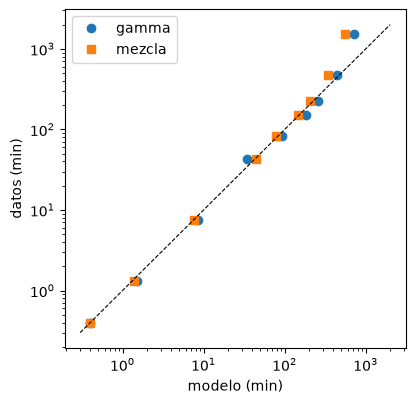

In [5]:
ps = np.array([.05, .1, .25, .5, .75, .9, .95, .99, .999])
def demora_cuantil(p, cual):
    if cual == "gamma": return gammaincinv(P["gamma"][0], p) * P["gamma"][1]
    q, a1, e1, a2, e2 = P["mezcla"]
    return gammaincinv(a1, p / q) * e1 if p < q else P["piso_mezcla"] + gammaincinv(a2, (p - q) / (1 - q)) * e2
obs = np.quantile(P["demoras"], ps)
tabla_q = pd.DataFrame({"datos": obs, "gamma": [demora_cuantil(p, "gamma") for p in ps], "mezcla": [demora_cuantil(p, "mezcla") for p in ps]},
                       index=[f"{p:.1%}" for p in ps]).round(1)
fig, ax = plt.subplots(figsize=(4.4, 4.4))
ax.loglog(tabla_q.gamma, tabla_q.datos, "o", label="gamma"); ax.loglog(tabla_q.mezcla, tabla_q.datos, "s", label="mezcla")
ax.loglog([.3, 2000], [.3, 2000], "k--", lw=.8); ax.set_xlabel("modelo (min)"); ax.set_ylabel("datos (min)"); ax.legend()
tabla_q

## Paso 2 · Una publicación sola, a mano

La entidad es la publicación. Nace en el evento publicar, que en AnyLogic sería un `Source`, y en cada vuelta del lazo se expone el frente, se marcan k reenvíos, se sortea el frente siguiente con un solo sorteo de Poisson de media Λ, y la publicación espera la demora entre generaciones. Cuando el frente queda vacío, muere (`Sink`).

El lazo siempre termina: g sube en cada vuelta y δ vale 0 en la generación más profunda de la muestra, así que Λ da 0 y no hay más hijos. El simulador lo controla con un `assert`.

Cada publicación, generación e ítem usan su propio generador sembrado con su número, para que dos alternativas vean las mismas publicaciones.

In [6]:
def poisson_inv(u, lam):                     # el menor k con F(k) ≥ u: el mismo u da el mismo k o uno vecino
    if lam > 300:
        return int(max(0, round(stats.norm.ppf(u, lam, np.sqrt(lam)))))
    k, p = 0, np.exp(-lam)
    c = p
    while u > c:
        k += 1; p *= lam / k; c += p
    return k

def binom_inv(u, n, q):
    k, p = 0, (1 - q) ** n
    c = p
    while u > c and k < n:
        k += 1; p *= (n - k + 1) / k * q / (1 - q); c += p
    return k

class RedBaires:
    def __init__(self, P, VD, semilla=1, escenario=None):
        self.P, self.VD, self.s = P, {**VD_HOY, **VD}, semilla
        self.E = {**ESCENARIO_BASE, **(escenario or {})}
        self.m_coord = P["m_coord"] if self.E["m_coord"] is None else self.E["m_coord"]
        self.t_rev = SUPUESTOS["tiempo_revision_seg"] if self.E["tiempo_revision_seg"] is None else self.E["tiempo_revision_seg"]
        self.env = simpy.Environment()
        self.moderadores = simpy.Resource(self.env, capacity=self.VD["c"])     # ResourcePool
        self.rng_llegadas = np.random.default_rng([semilla, 0])
        self.VR = dict(nocivas=0.0, legitimas=0.0, friccion_legit=0.0, items=0, buenas_bajadas=0, cuentas_dia=0)
        self.VE = {"cola": [(0, 0)], "ocupados": [(0, 0)], "vivas": [(0, 0)]}   # se escriben sólo en los eventos
        self.cola = self.vivas = 0
        self.N = dict(pub_creadas=0, pub_extintas=0, it_creados=0, it_piso=0, it_cola=0, it_rev=0, it_revisados=0)
        self.latencias, self.tamanos, self.lotes, self.traza = [], [], [], None
        self.con_moderacion, self.t_ini = True, 0

    def anotar(self, ve, valor):
        self.VE[ve].append((self.env.now, valor))

    def demora(self, u):
        if self.E["demora"] == "mezcla":                                # un solo u: los mismos números aleatorios
            p, a1, e1, a2, e2 = self.P["mezcla"]
            return gammaincinv(a1, u / p) * e1 if u < p else self.P["piso_mezcla"] + gammaincinv(a2, (u - p) / (1 - p)) * e2
        a, e = self.P["gamma"]
        return gammaincinv(a, u) * e

def p_marca(self, pub):
    if self.VD["clasificador"] is not None:                      # clasificador nuevo: (precisión, recall)
        prec, rec = self.VD["clasificador"]
        pi = self.P["frac_nociva_ev"]
        return rec if pub["nociva"] else rec * pi * (1 - prec) / (prec * (1 - pi))
    q = int(np.searchsorted(self.P["cortes_tox"], pub["tox"]))
    return self.P["p_marca"][int(pub["nociva"]), q]

def publicar(self, i):
    P, VD = self.P, self.VD
    rng = np.random.default_rng([self.s, 2, i])                  # atributos de la publicación
    s = P["semillas"].iloc[rng.integers(len(P["semillas"]))]
    pub = dict(id=i, nociva=bool(s.nociva), tox=s.toxicity_index, coord=bool(s.coord),
               sensible=s.tema.startswith(SUPUESTOS["temas_sensibles"]), f=0.0, acum=0)
    rec, prec, fc = P["recall_det"], P["precision_det"], P["frac_coord"]
    fp_det = rec * fc * (1 - prec) / (prec * (1 - fc))
    pub["detectada"] = VD["degradar"] and rng.random() < (rec if pub["coord"] else fp_det)
    if pub["detectada"] and s.tipo_i in P["grandes"]:
        self.VR["cuentas_dia"] += SUPUESTOS["dias_cobrados_por_deteccion"]
    frente = np.zeros(5); frente[s.tipo_i] = 1
    g, total = 0, 0
    self.N["pub_creadas"] += 1
    self.vivas += 1; self.anotar("vivas", self.vivas)
    while frente.sum() > 0:
        assert g < len(P["delta"]), "la publicación superó la generación máxima"
        rg = np.random.default_rng([self.s, 3, i, g])            # los mismos sorteos en cada generación
        u_hijos, u_marca, u_demora = rg.random(3)
        n = int(frente.sum()); total += n
        alcance = (1 - VD["d"]) if pub["detectada"] else 1.0
        seguidores = sum(P["seguidores"][t][rg.integers(len(P["seguidores"][t]), size=int(frente[t]))].sum()
                         for t in range(5) if frente[t])
        impresiones = P["imp_por_seguidor"] * seguidores * alcance      # 1. exponer
        self.VR["nocivas" if pub["nociva"] else "legitimas"] += impresiones
        k = binom_inv(u_marca, n, self.p_marca(pub))                     # 2. marcar
        if k and self.con_moderacion:
            v = (frente * P["verif"]).sum() / n
            self.env.process(self.moderar(pub, k, n, v, g))
        pub["acum"] += n                                                # 3. sortear el frente siguiente
        friccion = VD["umbral"] is not None and pub["acum"] >= VD["umbral"]
        if friccion and not pub["nociva"]:
            self.VR["friccion_legit"] += P["C"]["perdida_friccion"] * impresiones
        lam = ((frente * P["R"]).sum() * P["delta"][min(g, len(P["delta"]) - 1)]
               * (self.m_coord if pub["coord"] else 1) * (1 - VD["reduccion"] if friccion else 1)
               * (1 - pub["f"]) * alcance)
        hijos = poisson_inv(u_hijos, lam) if lam > 0 else 0
        if self.traza is not None:
            self.traza.append(dict(t=round(self.env.now), g=g, frente=frente.astype(int).tolist(), n=n,
                                   impresiones=round(impresiones), k=k, Λ=round(lam, 2), hijos=hijos))
        frente = np.bincount(rg.choice(5, size=hijos, p=P["p_hijo"]), minlength=5).astype(float)
        if hijos:
            yield self.env.timeout(self.demora(u_demora))               # 4. demora entre generaciones
        g += 1
    self.vivas -= 1; self.anotar("vivas", self.vivas)
    self.N["pub_extintas"] += 1
    self.tamanos.append(total)

RedBaires.p_marca, RedBaires.publicar = p_marca, publicar

Se sigue una publicación generación por generación, sin moderación, desde una semilla que arranca en una cuenta BROADCASTER.

In [7]:
sim = RedBaires(P, {}, semilla=3)
sim.traza, sim.con_moderacion = [], False             # la cola todavía no existe
i = next(i for i in range(500) if P["semillas"].iloc[np.random.default_rng([3, 2, i]).integers(len(P["semillas"]))].tipo_i == 0)
sim.env.process(sim.publicar(i))
sim.env.run()
pd.DataFrame(sim.traza)

,t,g,frente,n,impresiones,k,Λ,hijos
0,0,0,"[1, 0, 0, 0, 0]",1,33300,0,10.13,7
1,225,1,"[0, 1, 1, 0, 5]",7,20343,3,6.73,7
2,264,2,"[1, 0, 2, 0, 4]",7,82260,2,6.42,7
3,264,3,"[0, 0, 2, 0, 5]",7,8033,2,2.96,2
4,279,4,"[0, 0, 0, 0, 2]",2,104,0,0.74,0


## Paso 3 · La cola de moderación, a mano

El ítem de moderación es la segunda entidad. Nace cuando se marcan k reenvíos y hace este recorrido: `Delay` por el piso de la latencia → `Queue` FIFO → `Service` con un `ResourcePool` de c moderadores → `Sink`. La revisión es Erlang de k fases. Al terminar se sortea cuántos de los k se remueven y esa fracción se acumula de forma multiplicativa en la publicación: 1 − (1 − f)(1 − removidos/n).

Las variables de estado se anotan en el momento en que cambian. Además se lleva la cuenta de cada entidad, para poder controlar que todo lo que entra salga.

In [8]:
def moderar(self, pub, k, n, v, g=0):
    rm = np.random.default_rng([self.s, 4, pub.get("id", -1), g])     # el mismo ítem sortea lo mismo en todo escenario
    marca, S, lote = self.env.now, SUPUESTOS, [None, None, None, k]
    self.N["it_creados"] += 1; self.N["it_piso"] += 1
    yield self.env.timeout(self.P["piso_latencia"])                     # Delay
    self.N["it_piso"] -= 1; self.N["it_cola"] += 1
    self.cola += 1; self.anotar("cola", self.cola)                      # entra a la Queue
    lote[0] = self.env.now; self.lotes.append(lote)
    with self.moderadores.request() as pedido:                          # Seize
        yield pedido
        self.cola -= 1; self.anotar("cola", self.cola)
        self.N["it_cola"] -= 1; self.N["it_rev"] += 1
        lote[1] = self.env.now
        self.anotar("ocupados", self.moderadores.count)
        yield self.env.timeout(rm.gamma(k, self.t_rev / 60))            # Erlang(k), en minutos
    self.anotar("ocupados", self.moderadores.count)                     # Release
    lote[2] = self.env.now
    self.N["it_rev"] -= 1; self.N["it_revisados"] += 1
    self.latencias.append(self.env.now - marca)
    p = min(1.0, pub["tox"] * (S["factor_tema_sensible"] if pub["sensible"] else 1)
            * (1 - S["factor_verificada"] * v) * self.E["factor_remocion"])
    removidos = rm.binomial(k, p)
    pub["f"] = 1 - (1 - pub["f"]) * (1 - removidos / n)
    self.VR["items"] += k
    if not pub["nociva"]:
        self.VR["buenas_bajadas"] += removidos

RedBaires.moderar = moderar

Se prueba la cola sola, con seis ítems marcados en minutos elegidos a mano y un moderador. Ningún ítem puede tener una latencia menor al piso, y los que llegan juntos se ordenan uno detrás de otro.

In [9]:
sim = RedBaires(P, dict(c=1), semilla=1)
filas = []
def item_de_prueba(t, k):
    yield sim.env.timeout(t)
    pub = dict(id=t, tox=0.5, sensible=False, nociva=True, f=0.0)
    inicio = sim.env.now
    yield sim.env.process(sim.moderar(pub, k, n=10, v=0.0))
    filas.append(dict(marcado=t, k=k, llega_a_la_bandeja=t + 90, sale=round(sim.env.now, 1),
                      latencia=round(sim.env.now - t, 1)))
for t, k in [(0, 6), (0, 3), (0, 4), (5, 2), (30, 5), (31, 1)]:
    sim.env.process(item_de_prueba(t, k))
sim.env.run()
pd.DataFrame(filas)

,marcado,k,llega_a_la_bandeja,sale,latencia
0,0,6,90,91.7,91.7
1,0,3,90,92.5,92.5
2,0,4,90,93.6,93.6
3,5,2,95,96.1,91.1
4,30,5,120,120.7,90.7
5,31,1,121,121.3,90.3


## Paso 4 · Un día entero

Se juntan las dos ramas. El evento publicar es un `Source` con tasa por hora del día, multiplicada por el factor del día de la semana y por el volumen del escenario. La corrida arranca un lunes. Las funciones de esta celda calculan promedios ponderados por el tiempo a partir de los registros de cada variable de estado.

El peor episodio se define como las 24 horas consecutivas, con paso de una hora, con la cola de moderación promedio más alta de la parte medida. Se registra para cada corrida, con la ocupación, la cola y las publicaciones vivas de ese tramo, porque muestra si el consumo queda acotado.

In [10]:
def llegadas(self):
    i = 0
    while True:
        h, d = int(self.env.now // 60) % 24, int(self.env.now // 1440) % 7
        tasa = self.P["lam"][h] * self.P["semana"][d] * self.E["volumen"]
        yield self.env.timeout(self.rng_llegadas.exponential(1 / tasa))
        self.env.process(self.publicar(i))
        i += 1

def correr(self, dias, calentamiento=0):
    self.env.process(self.llegadas())
    if calentamiento:                                    # se descarta el transitorio
        self.env.run(until=calentamiento * 1440)
        self.VR = {k: 0 * v for k, v in self.VR.items()}
        self.latencias, self.tamanos = [], []
        self.t_ini = calentamiento * 1440
    self.env.run(until=(calentamiento + dias) * 1440)
    return self

RedBaires.llegadas, RedBaires.correr = llegadas, correr

def area_acumulada(serie, t_fin):
    t, v = map(np.array, zip(*serie))
    t = np.append(t, t_fin)
    return t, np.concatenate([[0.0], np.cumsum(np.diff(t) * v)])

def promedio_temporal(serie, t_ini, t_fin):
    t, a = area_acumulada(serie, t_fin)
    return (np.interp(t_fin, t, a) - np.interp(t_ini, t, a)) / (t_fin - t_ini)

def promedios_por_hora(serie, t_ini, t_fin):
    t, a = area_acumulada(serie, t_fin)
    return np.diff(np.interp(np.arange(t_ini, t_fin + 1, 60.0), t, a)) / 60

def maximo_en(serie, a, b):
    t, v = map(np.array, zip(*serie))
    return float(v[max(np.searchsorted(t, a, side="right") - 1, 0):np.searchsorted(t, b, side="right")].max())

def peor_episodio(r):
    t_ini, t_fin = r.t_ini, r.env.now
    cola = promedios_por_hora(r.VE["cola"], t_ini, t_fin)
    i = int(np.argmax(np.convolve(cola, np.ones(24) / 24, "valid")))
    a, b = t_ini + i * 60, t_ini + i * 60 + 1440
    return dict(pe_inicio_dia=a / 1440, pe_cola_media=promedio_temporal(r.VE["cola"], a, b), pe_cola_max=maximo_en(r.VE["cola"], a, b),
                pe_vivas_media=promedio_temporal(r.VE["vivas"], a, b), pe_vivas_max=maximo_en(r.VE["vivas"], a, b),
                pe_ocupacion=promedio_temporal(r.VE["ocupados"], a, b) / r.VD["c"])

def kpis(r):
    """Lo que se le muestra a la Dirección. Lo que hace falta para el costo sale de acá."""
    t_ini, t_fin, c = r.t_ini, r.env.now, r.VD["c"]
    ocup = promedios_por_hora(r.VE["ocupados"], t_ini, t_fin) / c
    perfil = pd.Series(ocup).groupby((int(t_ini / 60) + np.arange(len(ocup))) % 24).mean()
    return {**r.VR, "c": c, "clasificador_nuevo": r.VD["clasificador"] is not None,
            "lat_mediana": float(np.median(r.latencias)), "lat_media": float(np.mean(r.latencias)), "lat_p90": float(np.percentile(r.latencias, 90)),
            "tam_medio": float(np.mean(r.tamanos)), "tam_p90": float(np.percentile(r.tamanos, 90)), "tam_p99": float(np.percentile(r.tamanos, 99)),
            "tam_max": int(np.max(r.tamanos)), "publicaciones": len(r.tamanos),
            "ocupacion": promedio_temporal(r.VE["ocupados"], t_ini, t_fin) / c, "ocup_hora_max": float(perfil.max()), "ocup_hora_min": float(perfil.min()),
            "cola_media": promedio_temporal(r.VE["cola"], t_ini, t_fin), "vivas_media": promedio_temporal(r.VE["vivas"], t_ini, t_fin),
            **peor_episodio(r)}

def legitimas_perdidas(base, alt):
    """Las dos vías: las cascadas frenadas (contra la misma réplica de hoy) y la pérdida directa por fricción."""
    return (base["legitimas"] - alt["legitimas"]) + alt["friccion_legit"]

def costo_mes(alt, base, C):
    """Costo total por mes. Todos los términos en USD."""
    return (C["nociva"] * alt["nocivas"] + C["engagement"] * legitimas_perdidas(base, alt) + C["falso_positivo"] * alt["buenas_bajadas"]
            + C["item"] * alt["items"] + C["moderador_mes"] * alt["c"] + C["degradar_dia"] * alt["cuentas_dia"]
            + (C["clasificador_mes"] if alt["clasificador_nuevo"] else 0))

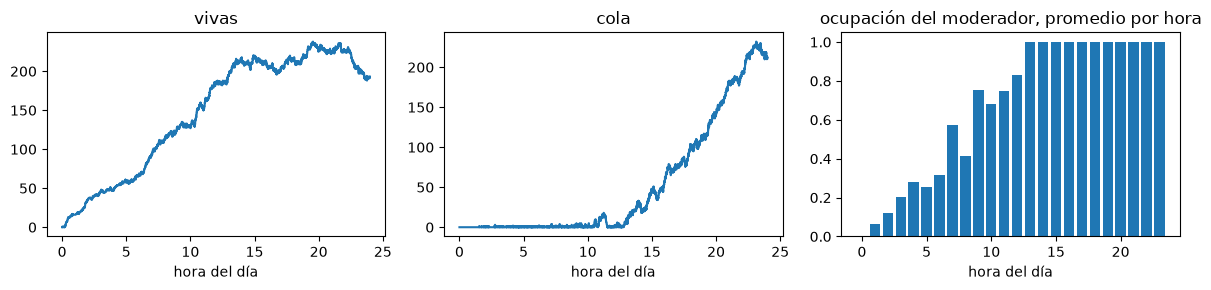

In [11]:
dia = RedBaires(P, dict(c=1), semilla=1).correr(dias=1)
fig, ejes = plt.subplots(1, 3, figsize=(12, 3))
for ax, ve in zip(ejes[:2], ["vivas", "cola"]):
    t, v = zip(*dia.VE[ve]); ax.step(np.array(t) / 60, v, where="post"); ax.set_title(ve); ax.set_xlabel("hora del día")
ejes[2].bar(range(24), promedios_por_hora(dia.VE["ocupados"], 0, 1440))
ejes[2].set_title("ocupación del moderador, promedio por hora"); ejes[2].set_xlabel("hora del día")
plt.tight_layout()

## Paso 5 · Calibración de la escala y validación

La escala es cuántas veces más grande que la muestra es la plataforma. No sale de los datos: se calibra para que la latencia mediana dé los 139 minutos observados. Como al corregir los hijos medios se marca menos contenido, la escala de la entrega B dejó de reproducir esa latencia y se volvió a ajustar, con todos los cambios de este notebook puestos.

Se probaron varias escalas con el horizonte de los experimentos, un mes con dos días de calentamiento, y varias semillas. La escala es frágil: cerca del valor elegido, un moderador pasa de alcanzar a quedar desbordado. Por eso se miden también las escalas vecinas.

In [12]:
def _medir(a):
    escala, s = a
    r = RedBaires(con_escala(P, escala), dict(c=1), semilla=s).correr(dias=30, calentamiento=2)
    return dict(escala=escala, semilla=s, lat_mediana=float(np.median(r.latencias)), cola_media=promedio_temporal(r.VE["cola"], r.t_ini, r.env.now),
                cola_max=max(x for _, x in r.VE["cola"]), ocupacion=promedio_temporal(r.VE["ocupados"], r.t_ini, r.env.now),
                tam_medio=float(np.mean(r.tamanos)), tam_p90=float(np.percentile(r.tamanos, 90)), tam_p99=float(np.percentile(r.tamanos, 99)),
                frac_nociva=r.VR["nocivas"] / (r.VR["nocivas"] + r.VR["legitimas"]))

In [13]:
import multiprocessing as mp
semillas_cal = range(1, 5)
with mp.get_context("fork").Pool(4) as pool:
    cal = pd.DataFrame(pool.map(_medir, [(e, s) for e in (P["escala"] - 2, P["escala"] - 1, P["escala"], P["escala"] + 1, P["escala"] + 2) for s in semillas_cal]))
cal.pivot(index="escala", columns="semilla", values="lat_mediana").round(0).assign(mediana=lambda t: t.median(axis=1))

semilla,1,2,3,4,mediana
escala,,,,,
55.3,108.0,115.0,105.0,112.0,110.0
56.3,119.0,129.0,119.0,118.0,119.0
57.3,134.0,155.0,141.0,131.0,137.5
58.3,159.0,204.0,188.0,150.0,173.5
59.3,188.0,472.0,212.0,185.0,200.0


In [14]:
tam_obs = datos.groupby("cascade_id").size()
lat_obs = datos.loc[datos.moderation_flag == 1, "moderation_latency_min"]
lat_obs = lat_obs[(lat_obs > 0) & (lat_obs < 1440)]
imp = datos.groupby("nociva").impressions.sum()
v = cal[cal.escala == P["escala"]]
pd.DataFrame({"observado": [lat_obs.median(), tam_obs.mean(), np.percentile(tam_obs, 90), np.percentile(tam_obs, 99), imp[True] / imp.sum()],
              "simulado (media de las semillas)": [v.lat_mediana.mean(), v.tam_medio.mean(), v.tam_p90.mean(), v.tam_p99.mean(), v.frac_nociva.mean()]},
             index=["latencia mediana (min)", "tamaño medio de la cascada", "tamaño p90", "tamaño p99", "fracción de impresiones nocivas"]).round(3)

,observado,simulado (media de las semillas)
latencia mediana (min),138.700,140.489
tamaño medio de la cascada,11.837,11.268
tamaño p90,28.500,31.250
tamaño p99,151.300,63.250
fracción de impresiones nocivas,0.408,0.396


## Paso 6 · Controles y tablero

Estos controles corren en cada réplica y frenan con un `assert` si algo no cierra:

1. ninguna latencia es menor que el piso;
2. todo lo que entra sale: publicaciones creadas = extinguidas + vivas, e ítems creados = revisados + en el piso + en la cola + en revisión;
3. la ley de Little en la cola, en su forma de trayectoria: el largo promedio de la cola tiene que dar la tasa de entrada por la espera promedio, medidas por separado con los registros de cada ítem;
4. la ocupación medida de los moderadores tiene que dar la tasa de entrada al servicio por el tiempo medio de revisión, dividido c.

El tablero de control es para el grupo, no para la Dirección. Se prende con `TABLERO = True` y muestra dónde están los cuellos de botella.

In [15]:
def controles(r, tol_little=.02, tol_ocup=.05):
    N, t_ini, t_fin, c = r.N, r.t_ini, r.env.now, r.VD["c"]
    assert r.P["delta"][-1] == 0, "δ final distinto de 0"
    if r.latencias:
        assert min(r.latencias) >= r.P["piso_latencia"], "latencia menor al piso"
    assert N["pub_creadas"] == N["pub_extintas"] + r.vivas, "publicaciones: creadas ≠ extinguidas + vivas"
    assert N["it_creados"] == N["it_revisados"] + N["it_piso"] + N["it_cola"] + N["it_rev"], "ítems: no se conservan"
    assert min(N.values()) >= 0, "algún contador quedó negativo"
    T = t_fin - t_ini
    L = promedio_temporal(r.VE["cola"], t_ini, t_fin)
    lotes = [x for x in r.lotes if x[0] < t_fin and (x[1] is None or x[1] > t_ini)]
    esperas = np.array([min(x[1] if x[1] is not None else t_fin, t_fin) - max(x[0], t_ini) for x in lotes])
    lam_cola, W = len(lotes) / T, esperas.mean() if len(lotes) else 0.0
    assert abs(L - lam_cola * W) <= tol_little * max(L, 1e-3) + 1e-6, f"Little: L = {L:.4f}, λW = {lam_cola * W:.4f}"
    ini = [x for x in r.lotes if x[1] is not None and t_ini <= x[1] < t_fin]
    ocup = promedio_temporal(r.VE["ocupados"], t_ini, t_fin) / c
    teorica = len(ini) / T * (np.mean([x[3] for x in ini]) * r.t_rev / 60 if ini else 0) / c
    assert abs(ocup - teorica) <= tol_ocup * max(ocup, teorica) + .005, f"ocupación: medida {ocup:.4f}, balanceo {teorica:.4f}"
    return dict(little_L=L, little_lamW=lam_cola * W, ocupacion=ocup, ocupacion_balanceo=teorica)

def tablero(r):
    if not TABLERO:
        return
    print(controles(r)); print(pd.Series(r.N).to_string())
    fig, ejes = plt.subplots(1, 3, figsize=(12, 3))
    for ax, ve in zip(ejes[:2], ["cola", "vivas"]):
        ax.plot(promedios_por_hora(r.VE[ve], r.t_ini, r.env.now)); ax.set_title(ve + ", promedio por hora"); ax.set_xlabel("hora de la corrida")
    ejes[2].plot(promedios_por_hora(r.VE["ocupados"], r.t_ini, r.env.now) / r.VD["c"]); ejes[2].set_title("ocupación"); ejes[2].set_xlabel("hora de la corrida")
    plt.tight_layout()

{'little_L': np.float64(125.53702830912181), 'little_lamW': np.float64(125.53702830912098), 'ocupacion': np.float64(0.9172792497241916), 'ocupacion_balanceo': np.float64(0.9169058641975308)}
pub_creadas     50631
pub_extintas    50439
it_creados      74151
it_piso           147
it_cola             0
it_rev              0
it_revisados    74004


nocivas                 960877856.31673
legitimas             1495794468.199371
friccion_legit                      0.0
items                            118833
buenas_bajadas                    21014
cuentas_dia                           0
c                                     1
clasificador_nuevo                False
lat_mediana                  129.743855
lat_media                    168.137004
lat_p90                      301.623392
tam_medio                     11.251492
tam_p90                            31.0
tam_p99                            63.0
tam_max                             172
publicaciones                     47580
ocupacion                      0.917279
ocup_hora_max                  0.996408
ocup_hora_min                  0.711665
cola_media                   125.537028
vivas_media                  195.181749
pe_inicio_dia                     13.75
pe_cola_media                535.140045
pe_cola_max                       699.0
pe_vivas_media               208.595248


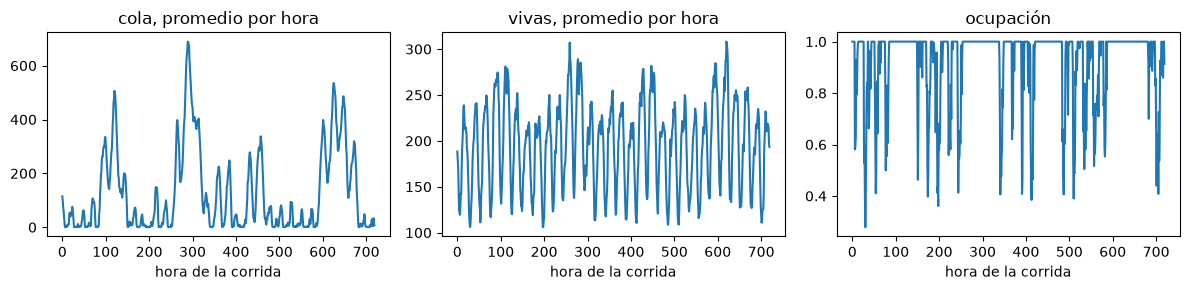

In [16]:
TABLERO = True
r = RedBaires(P, dict(c=1), semilla=11).correr(dias=30, calentamiento=2)
tablero(r)
TABLERO = False
pd.Series(kpis(r))